# Overview
This file alllows for re-producing all figures related to the observation analyses.


Expect a total run time of up to 10 minutes (tested on a laptop). (Tends to crash at the comparison section, just rerun it)

This produces Figures 1 and Supplementary 3, 4 and 5.

##### Beware: To run these specific calculations, you need to download the data files *ERA5_tasmax_World_allgrid.nc*, *HadEX3_TXx_1901-2018_ADW_61-90_1.25x1.875deg.nc*, *tasmax_World_All_MaxWorld_2016.nc* and *tasmax_World_All_MaxWorld_2017.nc*  from [Zenodo](https://doi.org/10.5281/zenodo.23558535).  Copy it in folder *./Data_origin/Other_datasets/* . See Github's file limitations.

In [2]:

import re 
import glob
import os

import numpy as np
import pandas as pd
import xarray as xr


import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator,FormatStrFormatter,MaxNLocator
import matplotlib.ticker as ticker
import matplotlib.lines as mlines
import matplotlib.patheffects as pe
#import matplotlib.colors as mcolors
plt.rcParams['figure.figsize'] = [7, 7]

import regionmask
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from math import radians, sin, cos, asin, sqrt



/home/barbauxo/miniconda3/envs/Cartes2/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)
ERROR 1: PROJ: proj_create_from_database: /home/barbauxo/miniconda3/envs/TestSDFC/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 2 whereas a number >= 4 is expected. It comes from another PROJ installation.


In [3]:
def standardize_lon(lon):
    """Convert 0-360 longitude convention to -180/180."""
    lon = np.asarray(lon, dtype=float)
    return np.where(lon > 180, lon - 360, lon)

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # km
    dlat, dlon = radians(lat2 - lat1), radians(lon2 - lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1))*cos(radians(lat2))*sin(dlon/2)**2
    return 2 * R * asin(sqrt(a))
def data_x_to_ax_frac(xd):
    return (xd - ax_xlim[0]) / (ax_xlim[1] - ax_xlim[0])

In [4]:

basepath=os.path.abspath(os.getcwd())
path_data=os.path.join(basepath,"Data_origin/") 
pathFig=os.path.join(basepath,"Figures_Datasets")
if not os.path.exists(pathFig):
    os.makedirs(pathFig)

# Time series (Figure 1)

/home/barbauxo/miniconda3/envs/Cartes2/lib/python3.13/site-packages/xarray/conventions.py:289: SerializationWarning: variable 'Ann' has multiple fill values {np.float64(-99.9), np.float32(-99.9)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)
/home/barbauxo/miniconda3/envs/Cartes2/lib/python3.13/site-packages/xarray/conventions.py:289: SerializationWarning: variable 'Jan' has multiple fill values {np.float64(-99.9), np.float32(-99.9)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)
/home/barbauxo/miniconda3/envs/Cartes2/lib/python3.13/site-packages/xarray/conventions.py:289: SerializationWarning: variable 'Feb' has multiple fill values {np.float64(-99.9), np.float32(-99.9)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)
/home/barbauxo/miniconda3/envs/Cartes2/lib/python3.13/site-packages/xarray/conventions.py:289: SerializationWarning: variable 'Mar' has multiple fill values {np.float64(-99.9), np.float32(-9

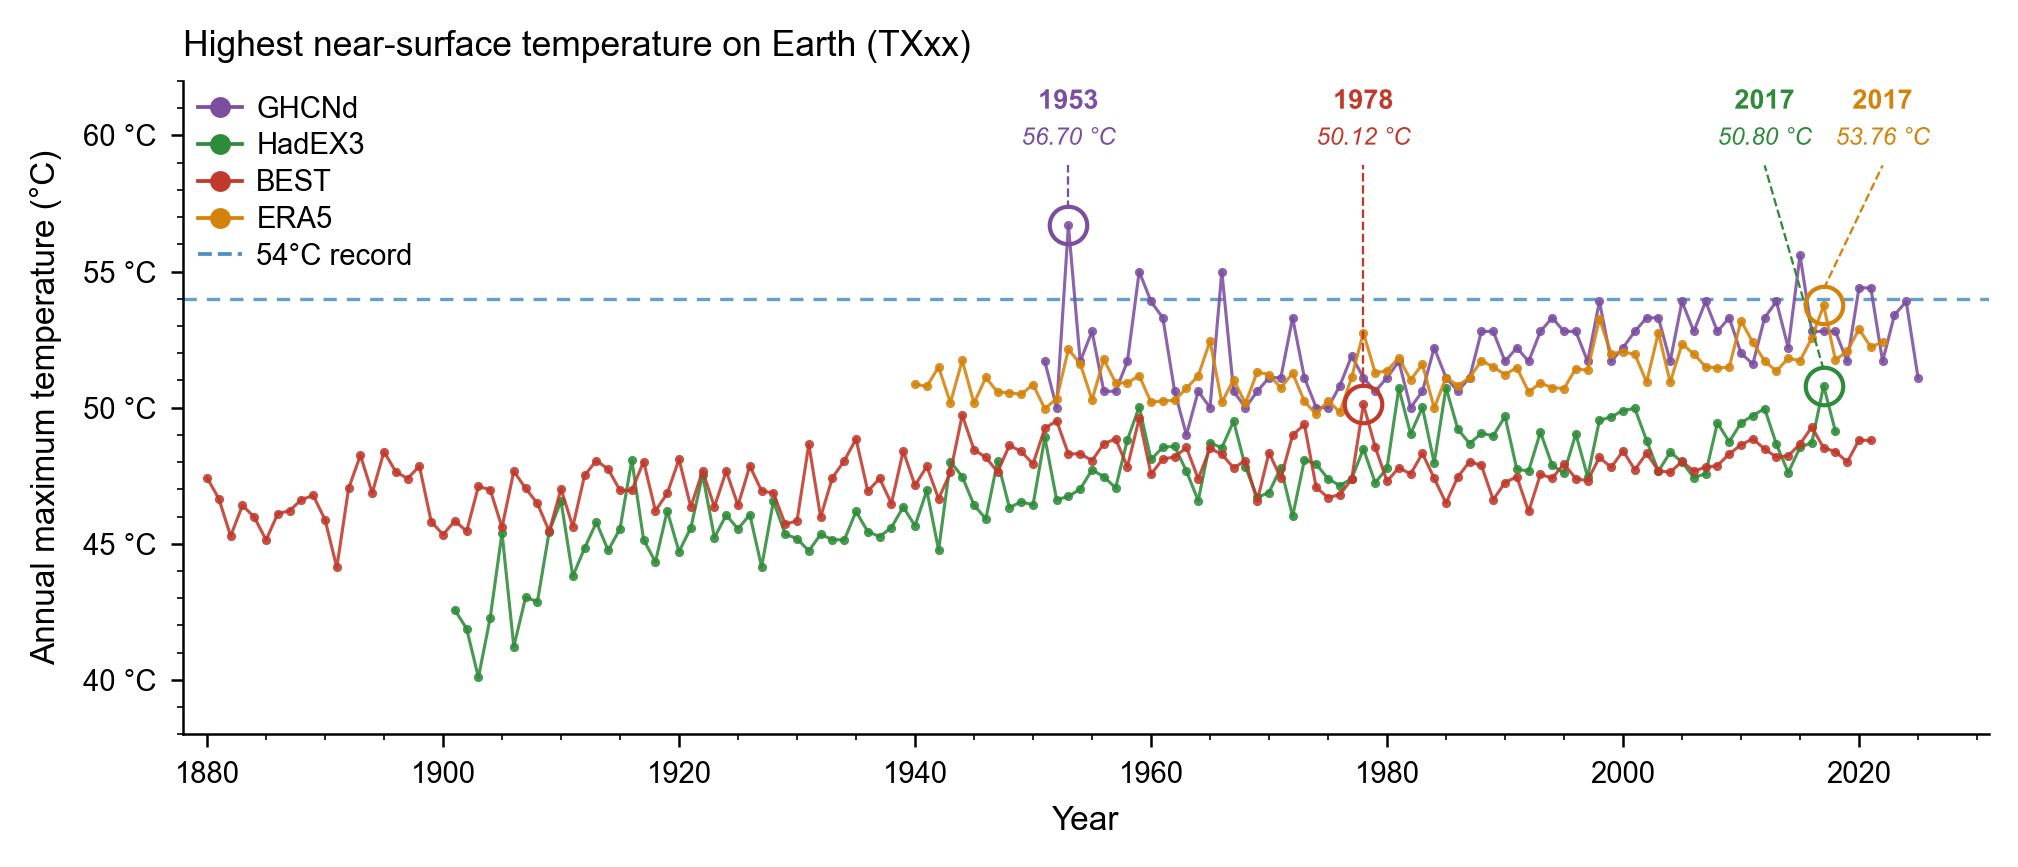

In [4]:

TXX_ERA5_025 = xr.open_dataset(
    path_data + 'ERA5_025_Obs_TXX_World/ERA5_tasmax_World.nc',
    decode_times=False)
TXX_ERA5_025 = pd.DataFrame(
    TXX_ERA5_025.tas.values.squeeze() - 273.15,
    columns=["tasmax"],
    index=TXX_ERA5_025.time.values + 1900)
 
TXX_HadEx3_grid = xr.open_dataset(
    path_data + "Other_datasets/HadEX3_TXx_1901-2018_ADW_61-90_1.25x1.875deg.nc")
TXX_HadEx3_grid = TXX_HadEx3_grid.max(
    dim=["longitude", "latitude"], skipna=True, keep_attrs=True)
TXX_HadEx3_grid = pd.DataFrame(
    TXX_HadEx3_grid.Ann.values.squeeze(),
    columns=["tasmax"],
    index=TXX_HadEx3_grid.time.values)
 
TXX_BEST_grid = xr.open_dataset(
    path_data + "Other_datasets/"
    "BEST_Berkeley_Earth_Surface_Temperature_1880_2021_TXx_ANN_RawData_"
    "1880-2021_-84to84_-180to180.nc",
    decode_times=False)
TXX_BEST_grid = TXX_BEST_grid.max(
    dim=["lon", "lat"], skipna=True, keep_attrs=True)
TXX_BEST_grid = pd.DataFrame(
    TXX_BEST_grid.TXx.values.squeeze(),
    columns=["tasmax"],
    index=TXX_BEST_grid.time.values.astype(int) + 1880)
 
TXX_GHCNDEX = pd.read_csv(path_data + "Other_datasets/GHCNDEX_annual_maxima_txx.csv")
TXX_GHCNDEX = TXX_GHCNDEX[TXX_GHCNDEX["year"] > 1950]
 
datasets = {
    "GHCNd": (TXX_GHCNDEX["year"].values,       TXX_GHCNDEX["annual_max"].values),
    "HadEX3":  (TXX_HadEx3_grid.index.values,      TXX_HadEx3_grid["tasmax"].values),
    "BEST":    (TXX_BEST_grid.index.values,         TXX_BEST_grid["tasmax"].values),
    "ERA5":    (TXX_ERA5_025.index.values,           TXX_ERA5_025["tasmax"].values),
}
 
plt.rcParams.update({
    "font.family":        "sans-serif",
    "font.sans-serif":    ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size":          8,
    "axes.labelsize":     8,
    "xtick.labelsize":    7,
    "ytick.labelsize":    7,
    "legend.fontsize":    7,
    "axes.linewidth":     0.6,
    "xtick.major.width":  0.6,  "ytick.major.width":  0.6,
    "xtick.minor.width":  0.4,  "ytick.minor.width":  0.4,
    "xtick.major.size":   3,    "ytick.major.size":   3,
    "xtick.minor.size":   1.5,  "ytick.minor.size":   1.5,
    "xtick.direction":    "out","ytick.direction":    "out",
    "axes.spines.top":    False,"axes.spines.right":  False,
    "figure.dpi":         300,  "savefig.dpi":        300,
})
 
C = {
    "GHCNd": "#7B4EA0",   # muted purple
    "HadEX3":  "#2E8B3A",   # forest green
    "BEST":    "#C0392B",   # brick red
    "ERA5":    "#D4820A",   # amber
    "ref":     "#4A90C4",   # steel blue
}
ORDER = ["GHCNd", "HadEX3", "BEST", "ERA5"]
 
peaks = []
for name in ORDER:
    x, y = datasets[name]
    idx  = int(np.argmax(y))
    peaks.append(dict(name=name, year=int(x[idx]), val=float(y[idx]), color=C[name]))
 
peaks.sort(key=lambda p: (p["year"], ORDER.index(p["name"])))
 
fig, ax = plt.subplots(figsize=(7.08, 3.35))
fig.subplots_adjust(left=0.08, right=0.93, top=0.78, bottom=0.13)
 
for name in ORDER:
    x, y = datasets[name]
    ax.plot(x, y,
            color=C[name], linewidth=0.75,
            marker="o", markersize=2.2,
            markerfacecolor=C[name], markeredgewidth=0,
            label=name, zorder=3, alpha=0.88)
 
ax.axhline(54, color=C["ref"], linewidth=0.8, linestyle=(0, (4, 3)),
           zorder=2, alpha=0.85)

all_x = np.concatenate([datasets[n][0] for n in ORDER])
ax_xlim = (int(all_x.min()) - 2, int(all_x.max()) + 6)
ax_ylim = (38, 62)
ax.set_xlim(*ax_xlim)
ax.set_ylim(*ax_ylim)
 

 

NUDGE_HALF = 5   
 
year_groups = {}
for p in peaks:
    year_groups.setdefault(p["year"], []).append(p["name"])
 
nudge = {}
for yr, names in year_groups.items():
    if len(names) == 2:
        nudge[names[0]] = -NUDGE_HALF
        nudge[names[1]] = +NUDGE_HALF
 
LABEL_Y_AX = 0.95   
 
for p in peaks:
    xp, yp = p["year"], p["val"]
    color   = p["color"]
    name    = p["name"]
    xl      = xp + nudge.get(name, 0)   
 
    xl_frac = data_x_to_ax_frac(xl)
    xp_frac = data_x_to_ax_frac(xp)
 
    ax.plot(xp, yp,
            marker="o", markersize=9,
            markerfacecolor="none",
            markeredgecolor=color,
            markeredgewidth=1.0,
            zorder=5, clip_on=True)
 
    ax.plot([xp, xl], [yp + 0.6, 0.95*ax_ylim[1]],
            color=color, lw=0.55, ls="--",
            zorder=4, clip_on=False,
            transform=ax.transData)
    t1 = ax.text(
        xl_frac, LABEL_Y_AX, f"{p['year']}",
        transform=ax.transAxes,
        fontsize=6.5, fontweight="semibold",
        color=color, ha="center", va="bottom",
        zorder=6, clip_on=False,
    )
    t1.set_path_effects([pe.withStroke(linewidth=2, foreground="white")])
 
    t2 = ax.text(
        xl_frac, LABEL_Y_AX - 0.055,
        f" \n{p['val']:.2f} °C",
        transform=ax.transAxes,
        fontsize=5.8, fontstyle="italic",
        color=color, ha="center", va="bottom",
        linespacing=1.35,
        zorder=6, clip_on=False,
    )
    t2.set_path_effects([pe.withStroke(linewidth=2, foreground="white")])
 
ax.yaxis.set_major_locator(ticker.MultipleLocator(5))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(v)} °C"))
 
ax.set_xlabel("Year", labelpad=4)
ax.set_ylabel("Annual maximum temperature (°C)", labelpad=5) #Annual maximum temperature 
ax.set_title(
    "Highest near-surface temperature on Earth (TXxx)",
    loc="left", pad=6, fontsize=8.5, fontweight="regular",
)
 
handles = [
    mlines.Line2D([], [], color=C[n], marker="o", markersize=4,
                  linewidth=0.9, label=n)
    for n in ORDER
]
ref_h = mlines.Line2D([], [], color=C["ref"], linewidth=0.9,
                       linestyle="--", label="54°C record")
ax.legend(
    handles=handles + [ref_h],
    loc="upper left", frameon=False,
    ncol=1, handlelength=1.5, handletextpad=0.5,
    labelspacing=0.3, borderpad=0,
)
 
plt.savefig(os.path.join(pathFig, "TXX_World_v4.pdf"), bbox_inches="tight")
plt.savefig(os.path.join(pathFig, "TXX_World_v4.png"), bbox_inches="tight", dpi=300)
plt.show()
 


# 4-Maps grid (Figure 3, supplementary)

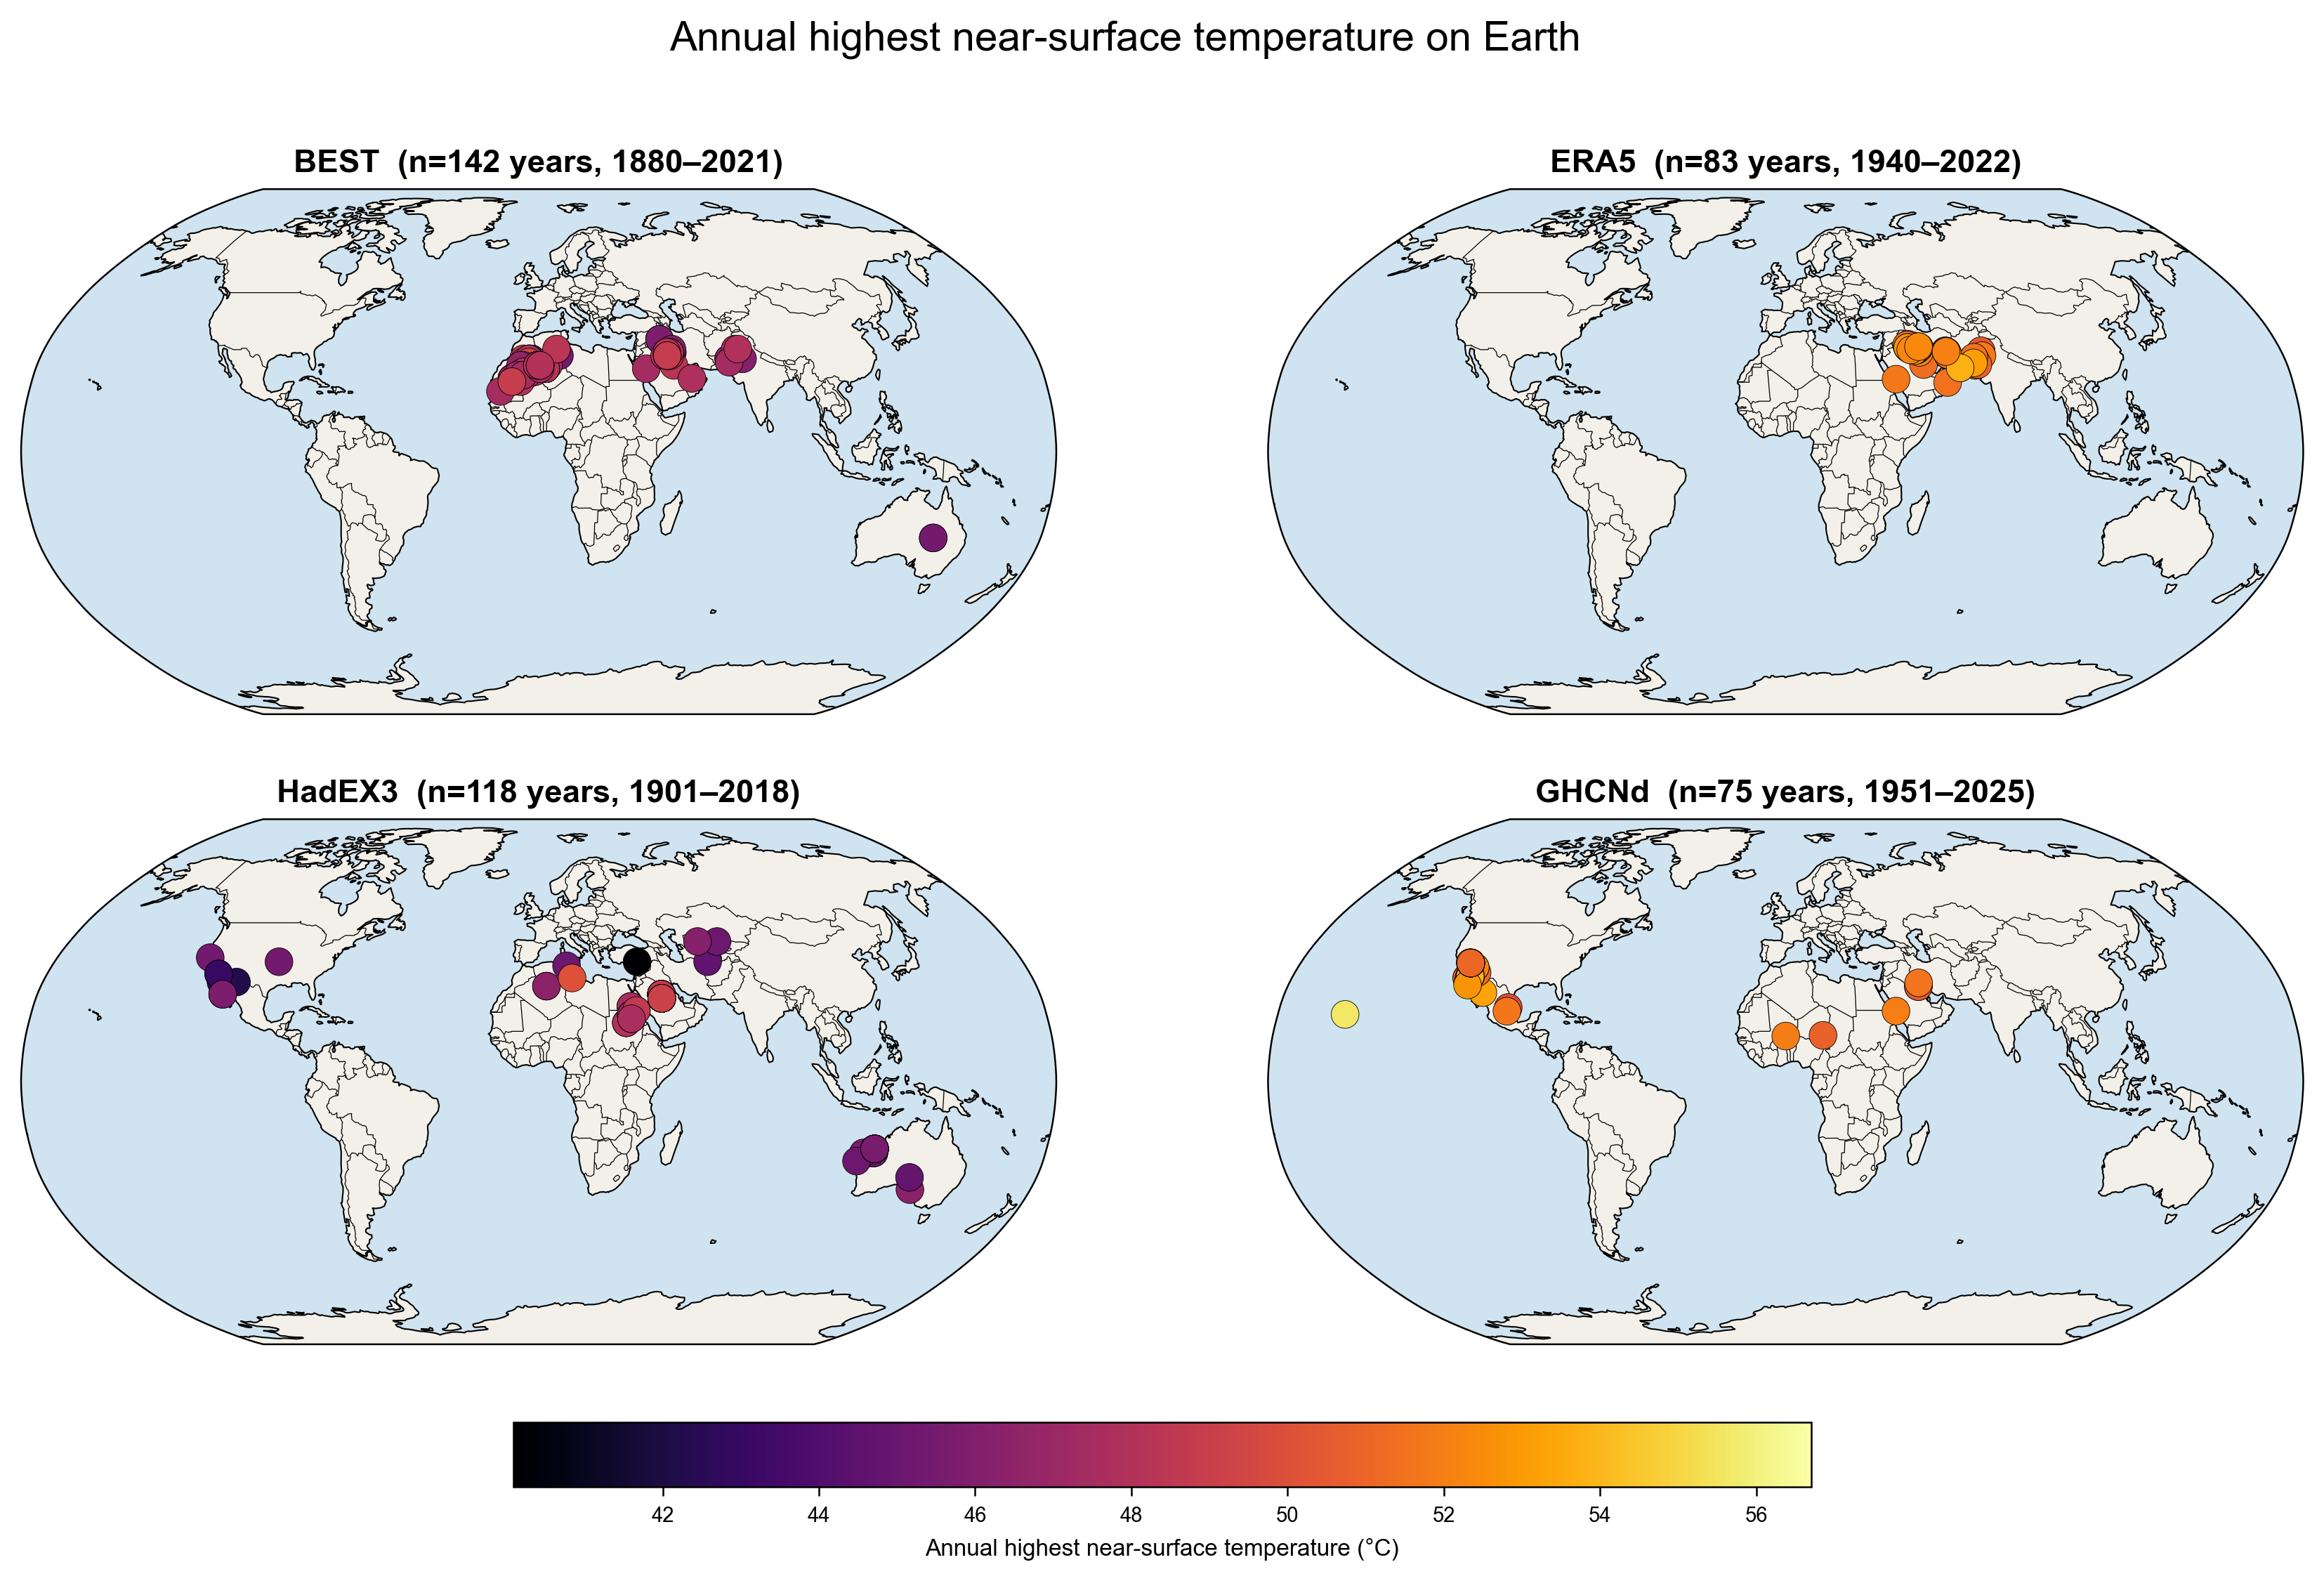

In [5]:
#Map BEST 

ds = xr.open_dataset(path_data+"/Other_datasets/BEST_Berkeley_Earth_Surface_Temperature_1880_2021_TXx_ANN_RawData_1880-2021_-84to84_-180to180.nc",decode_times=False)
txx = ds["TXx"] 

stacked = txx.stack(latlon=("lat", "lon"))
argmax_idx = stacked.argmax(dim="latlon", skipna=True)
max_values = stacked.max(dim="latlon", skipna=True)

max_lat = stacked["lat"].isel(latlon=argmax_idx)
max_lon = stacked["lon"].isel(latlon=argmax_idx)


years = ds["time"].values.astype(int) + 1880  # "years since 1880-01-01"

df_annual_max = pd.DataFrame({
    "year": years,
    "txx_max": max_values.values,
    "lat": max_lat.values,
    "lon": max_lon.values,
})


df_best = df_annual_max.rename(columns={"txx_max": "tmax_c"})[["year", "tmax_c", "lat", "lon"]].copy()
df_best["lon"] = standardize_lon(df_best["lon"])
# GHCNd

df_ghcnd = TXX_GHCNDEX.rename(columns={
    "annual_max": "tmax_c",
    "latitude": "lat",
    "longitude": "lon",
})[["year", "tmax_c", "lat", "lon"]]
df_ghcnd["lon"] = standardize_lon(df_ghcnd["lon"])

#HadEX3
df_hadex = pd.read_csv(
    path_data+"/Other_datasets/Where_Max_Hadex3.txt",
    sep=r"\s+", skiprows=1,
    names=["date", "name", "value", "lat", "lon"],
)
df_hadex["year"] = pd.to_datetime(df_hadex["date"]).dt.year
df_hadex = df_hadex.rename(columns={"value": "tmax_c"})[["year", "tmax_c", "lat", "lon"]]
df_hadex["lon"] = standardize_lon(df_hadex["lon"])

#ERA5

ds_era5 = xr.open_dataset(path_data+"/Other_datasets/ERA5_tasmax_World_allgrid.nc",decode_times=False)
tas = ds_era5["tas"]

stacked = tas.stack(latlon=("latitude", "longitude"))
argmax_idx = stacked.argmax(dim="latlon", skipna=True)
max_values = stacked.max(dim="latlon", skipna=True)
max_lat = stacked["latitude"].isel(latlon=argmax_idx)
max_lon = stacked["longitude"].isel(latlon=argmax_idx)

years_era5 = ds_era5["time"].values.astype(int) + 1900  # "years since 1900-1-1"

df_era5 = pd.DataFrame({
    "year": years_era5,
    "tmax_c": max_values.values - 273.15,   # Kelvin -> Celsius
    "lat": max_lat.values,
    "lon": max_lon.values,
})
df_era5["lon"] = standardize_lon(df_era5["lon"])



datasets = {
    "BEST": df_best,
    "ERA5": df_era5,
    "HadEX3": df_hadex,
    "GHCNd": df_ghcnd,
}

vmin = min(df["tmax_c"].min() for df in datasets.values())
vmax = max(df["tmax_c"].max() for df in datasets.values())

fig, axes = plt.subplots(
    2, 2, figsize=(14, 8),
    subplot_kw={"projection": ccrs.Robinson()}
)

    
for ax, (name, df) in zip(axes.flat, datasets.items()):
    ax.add_feature(cfeature.OCEAN, facecolor="#cfe3f0", zorder=0)   
    ax.add_feature(cfeature.LAND, facecolor="#f2f0e9", zorder=0)    
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=1)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, zorder=1)
    ax.set_global()
    sc = ax.scatter(
        df["lon"], df["lat"],
        c=df["tmax_c"], cmap="inferno",
        vmin=vmin, vmax=vmax,
        s=90, transform=ccrs.PlateCarree(), #20
        edgecolor="k", linewidth=0.2, zorder=3,
    )
    ax.set_title(f"{name}  (n={len(df)} years, {df['year'].min()}–{df['year'].max()})",
                 fontsize=11, fontweight="bold")
    
    

cbar = fig.colorbar(sc, ax=axes, orientation="horizontal", fraction=0.05, pad=0.06)
cbar.set_label("Annual highest near-surface temperature (°C)")

fig.suptitle("Annual highest near-surface temperature on Earth", fontsize=14)

plt.savefig(os.path.join(pathFig, "TXX_World_map.pdf"), bbox_inches="tight")
plt.savefig(os.path.join(pathFig, "TXX_World_map.png"), bbox_inches="tight", dpi=300)
plt.show()

# Turbat 2017 records - ERA5 Comparison (Figure 5 Supplementary)

In [6]:
ds_daily = xr.open_dataset(path_data+"/Other_datasets/tasmax_World_All_MaxWorld_2017.nc")  # adjust path/filename
tas_daily = ds_daily["tas"].sel(time="2017")              # Kelvin, dims (time, lat, lon)

values = tas_daily.values  # (ndays, nlat, nlon)
flat_idx = np.nanargmax(values)
it, ilat, ilon = np.unravel_index(flat_idx, values.shape)

max_value_c = values[it, ilat, ilon] - 273.15
max_date = tas_daily["time"].values[it]
max_lat = float(tas_daily["latitude"].values[ilat])
max_lon = float(tas_daily["longitude"].values[ilon])
max_lon_180 = max_lon - 360 if max_lon > 180 else max_lon

print(f"2017 global max: {max_value_c:.2f} °C on {max_date} "
      f"at ({max_lat:.3f}°N, {max_lon_180:.3f}°E)")
      
#25°59′N, 63°04′E   25.983333 63.066667
turbat_lat, turbat_lon = 25.983333, 63.066667



dist_km = haversine(max_lat, max_lon_180, turbat_lat, turbat_lon)      
field_day = tas_daily.sel(time="2017-05-28").squeeze() - 273.15 
field_day = field_day.sel(latitude=slice(35, 15), longitude=slice(50, 75))

2017 global max: 53.76 °C on 2017-05-29T11:00:00.000000000 at (25.750°N, 62.500°E)


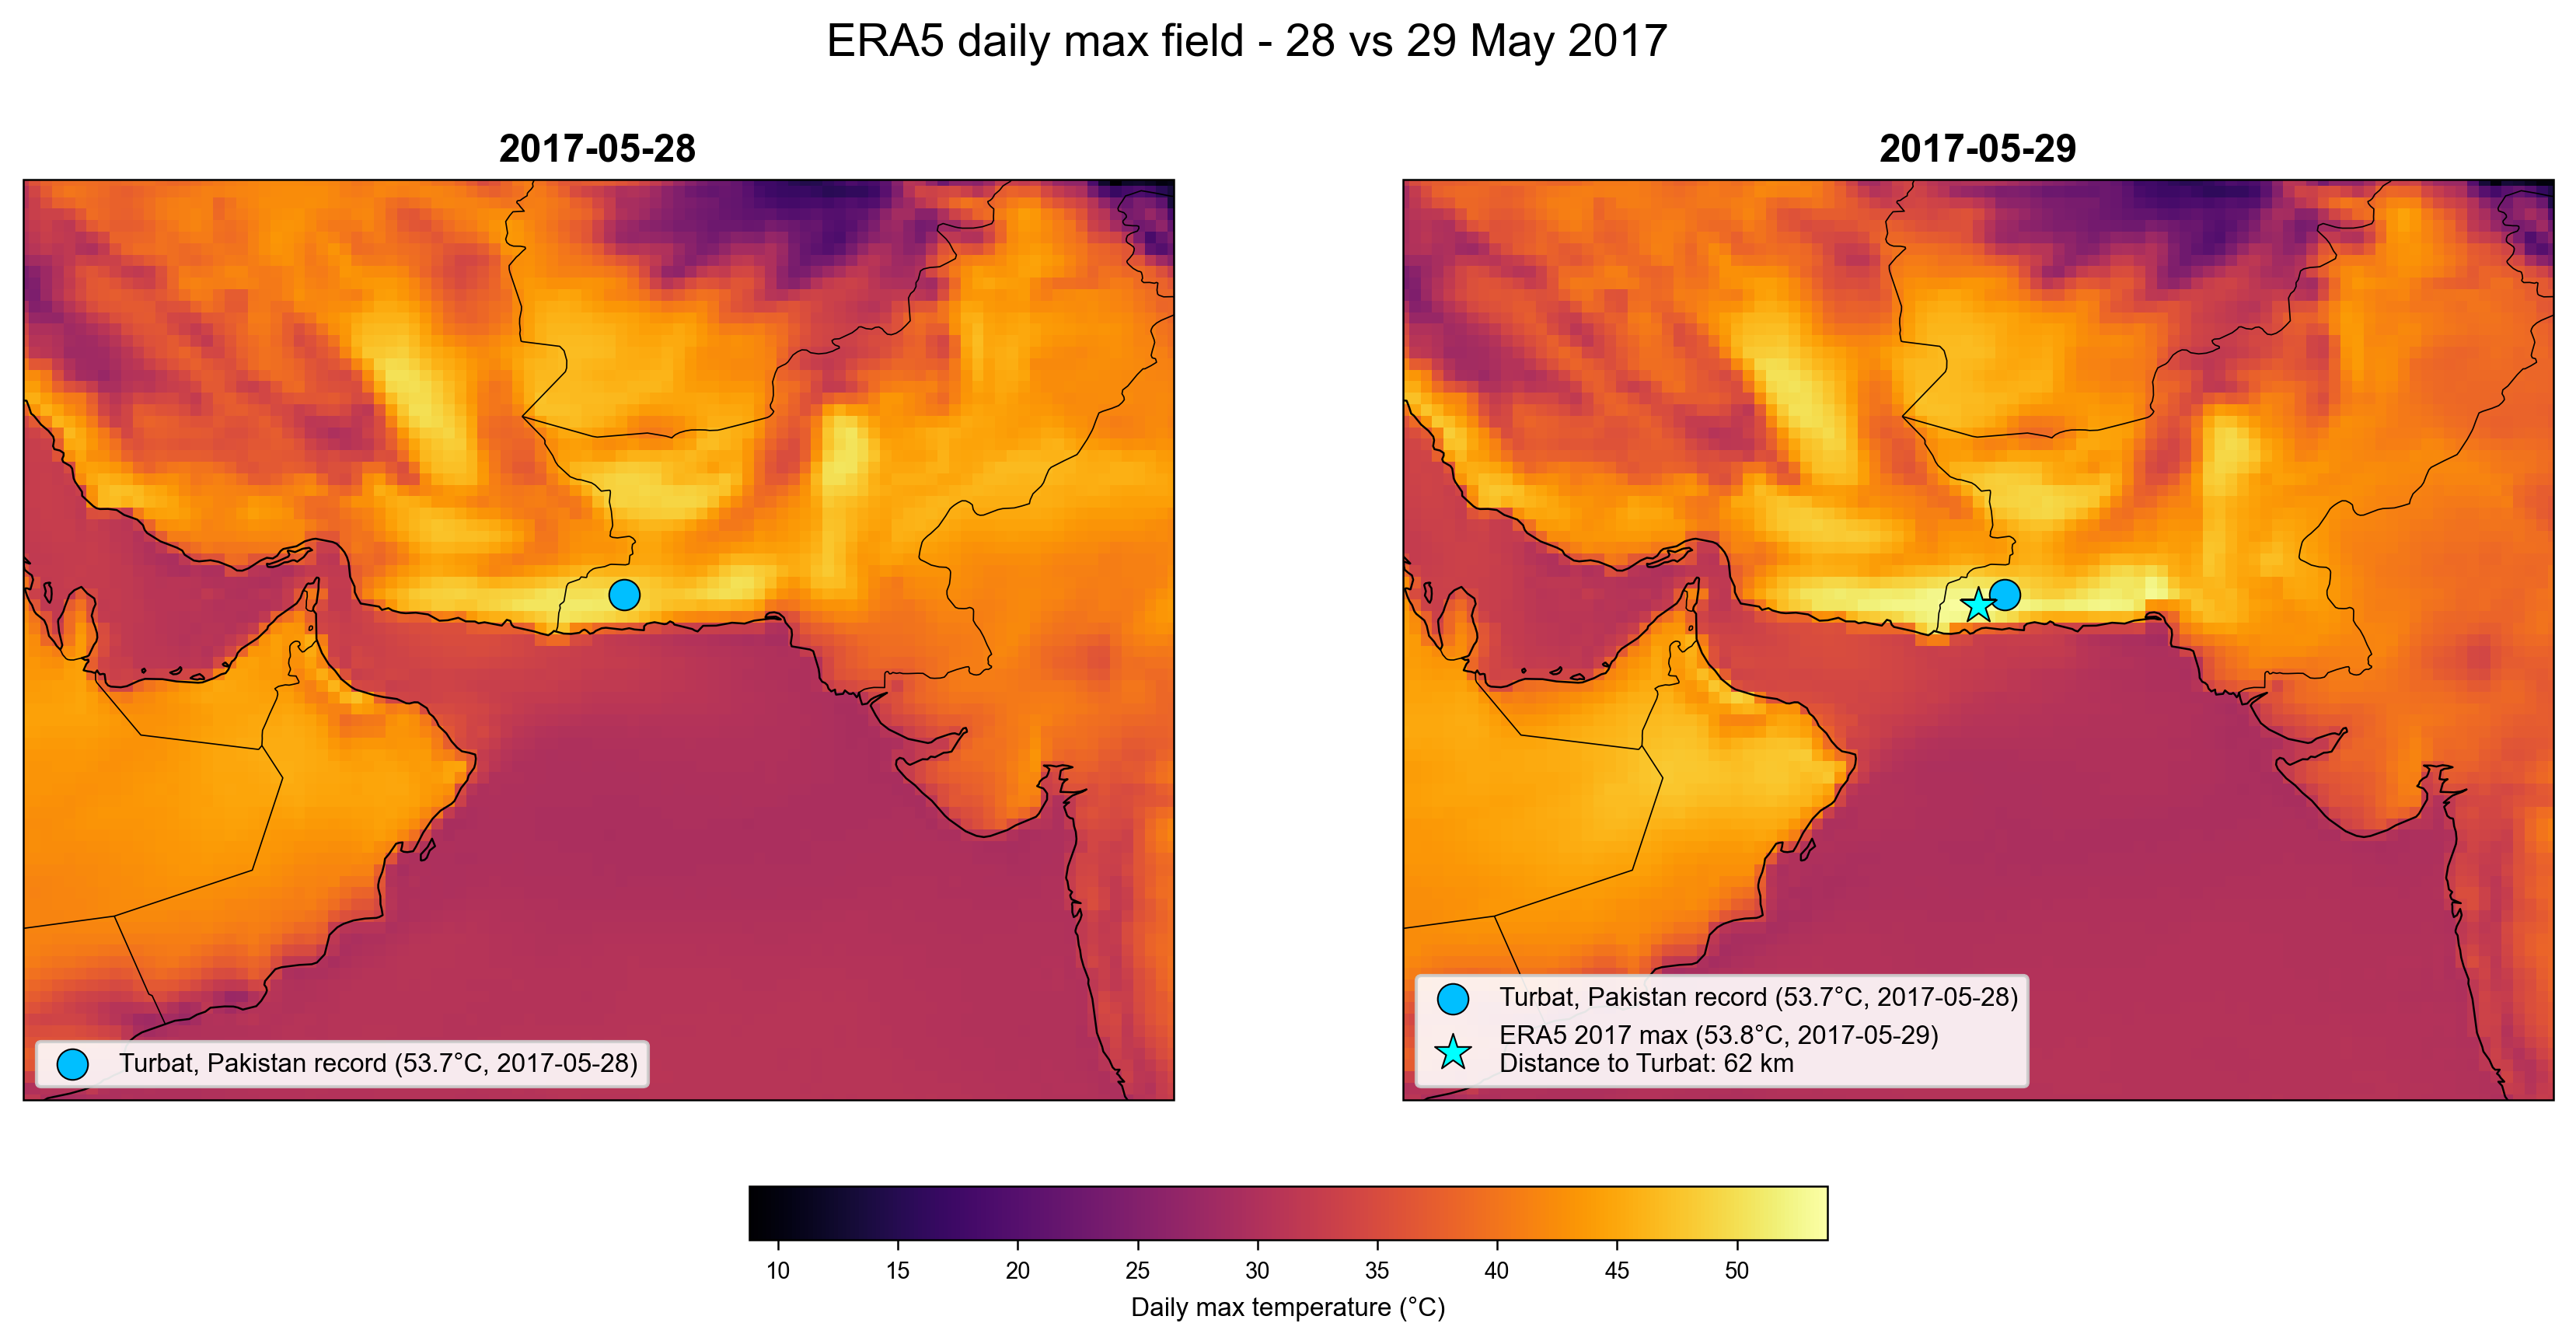

In [7]:
dates = ["2017-05-28", "2017-05-29"]

fields = {}
for d in dates:
    f = tas_daily.sel(time=d).squeeze() - 273.15
    f = f.sel(latitude=slice(35, 15), longitude=slice(50, 75))
    fields[d] = f

vmin = min(f.min().item() for f in fields.values())
vmax = max(f.max().item() for f in fields.values())

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for ax, d in zip(axes, dates):
    field_day = fields[d]
    ax.set_extent([50, 75, 15, 35], crs=ccrs.PlateCarree())

    mesh = ax.pcolormesh(
        field_day["longitude"], field_day["latitude"], field_day,
        cmap="inferno", shading="auto", vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree(), zorder=1,
    )
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=2)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4, zorder=2)

    ax.scatter(turbat_lon, turbat_lat, color="deepskyblue", s=90, marker="o",
               edgecolor="k", linewidth=0.5,
               transform=ccrs.PlateCarree(), zorder=5, label="Turbat, Pakistan record (53.7°C, 2017-05-28)")

    if d == str(max_date)[:10]:
        ax.scatter(max_lon_180, max_lat, color="cyan", s=140, marker="*",
                   edgecolor="k", linewidth=0.5,
                   transform=ccrs.PlateCarree(), zorder=5,
                   label=f"ERA5 2017 max ({max_value_c:.1f}°C, {str(max_date)[:10]}) \nDistance to Turbat: {dist_km:.0f} km")

    ax.legend(loc="lower left", fontsize=8, framealpha=0.9)
    ax.set_title(d, fontsize=12, fontweight="bold")

cbar = fig.colorbar(mesh, ax=axes, orientation="horizontal", fraction=0.05, pad=0.08)
cbar.set_label("Daily max temperature (°C)")

fig.suptitle("ERA5 daily max field - 28 vs 29 May 2017", fontsize=14)
plt.savefig(os.path.join(pathFig, "Comparison_Turbat_map.pdf"), bbox_inches="tight")

plt.show()

# Mitribah 2016 record - ERA5 Comparison (Figure 4 Supplementary)

In [8]:
ds_daily = xr.open_dataset(path_data+"/Other_datasets/tasmax_World_All_MaxWorld_2016.nc")  # adjust path/filename
tas_daily = ds_daily["tas"].sel(time="2016")              # Kelvin, dims (time, lat, lon)

values = tas_daily.values  # (ndays, nlat, nlon)
flat_idx = np.nanargmax(values)
it, ilat, ilon = np.unravel_index(flat_idx, values.shape)

max_value_c = values[it, ilat, ilon] - 273.15
max_date = tas_daily["time"].values[it]
max_lat = float(tas_daily["latitude"].values[ilat])
max_lon = float(tas_daily["longitude"].values[ilon])
max_lon_180 = max_lon - 360 if max_lon > 180 else max_lon

print(f"2016 global max: {max_value_c:.2f} °C on {max_date} "
      f"at ({max_lat:.3f}°N, {max_lon_180:.3f}°E)")

#29°49′N, 47°21E   29.81666747.350000
turbat_lat, turbat_lon = 29.816667,47.350000
dist_km = haversine(max_lat, max_lon_180, turbat_lat, turbat_lon)

2016 global max: 52.55 °C on 2016-07-22T11:00:00.000000000 at (31.250°N, 47.500°E)


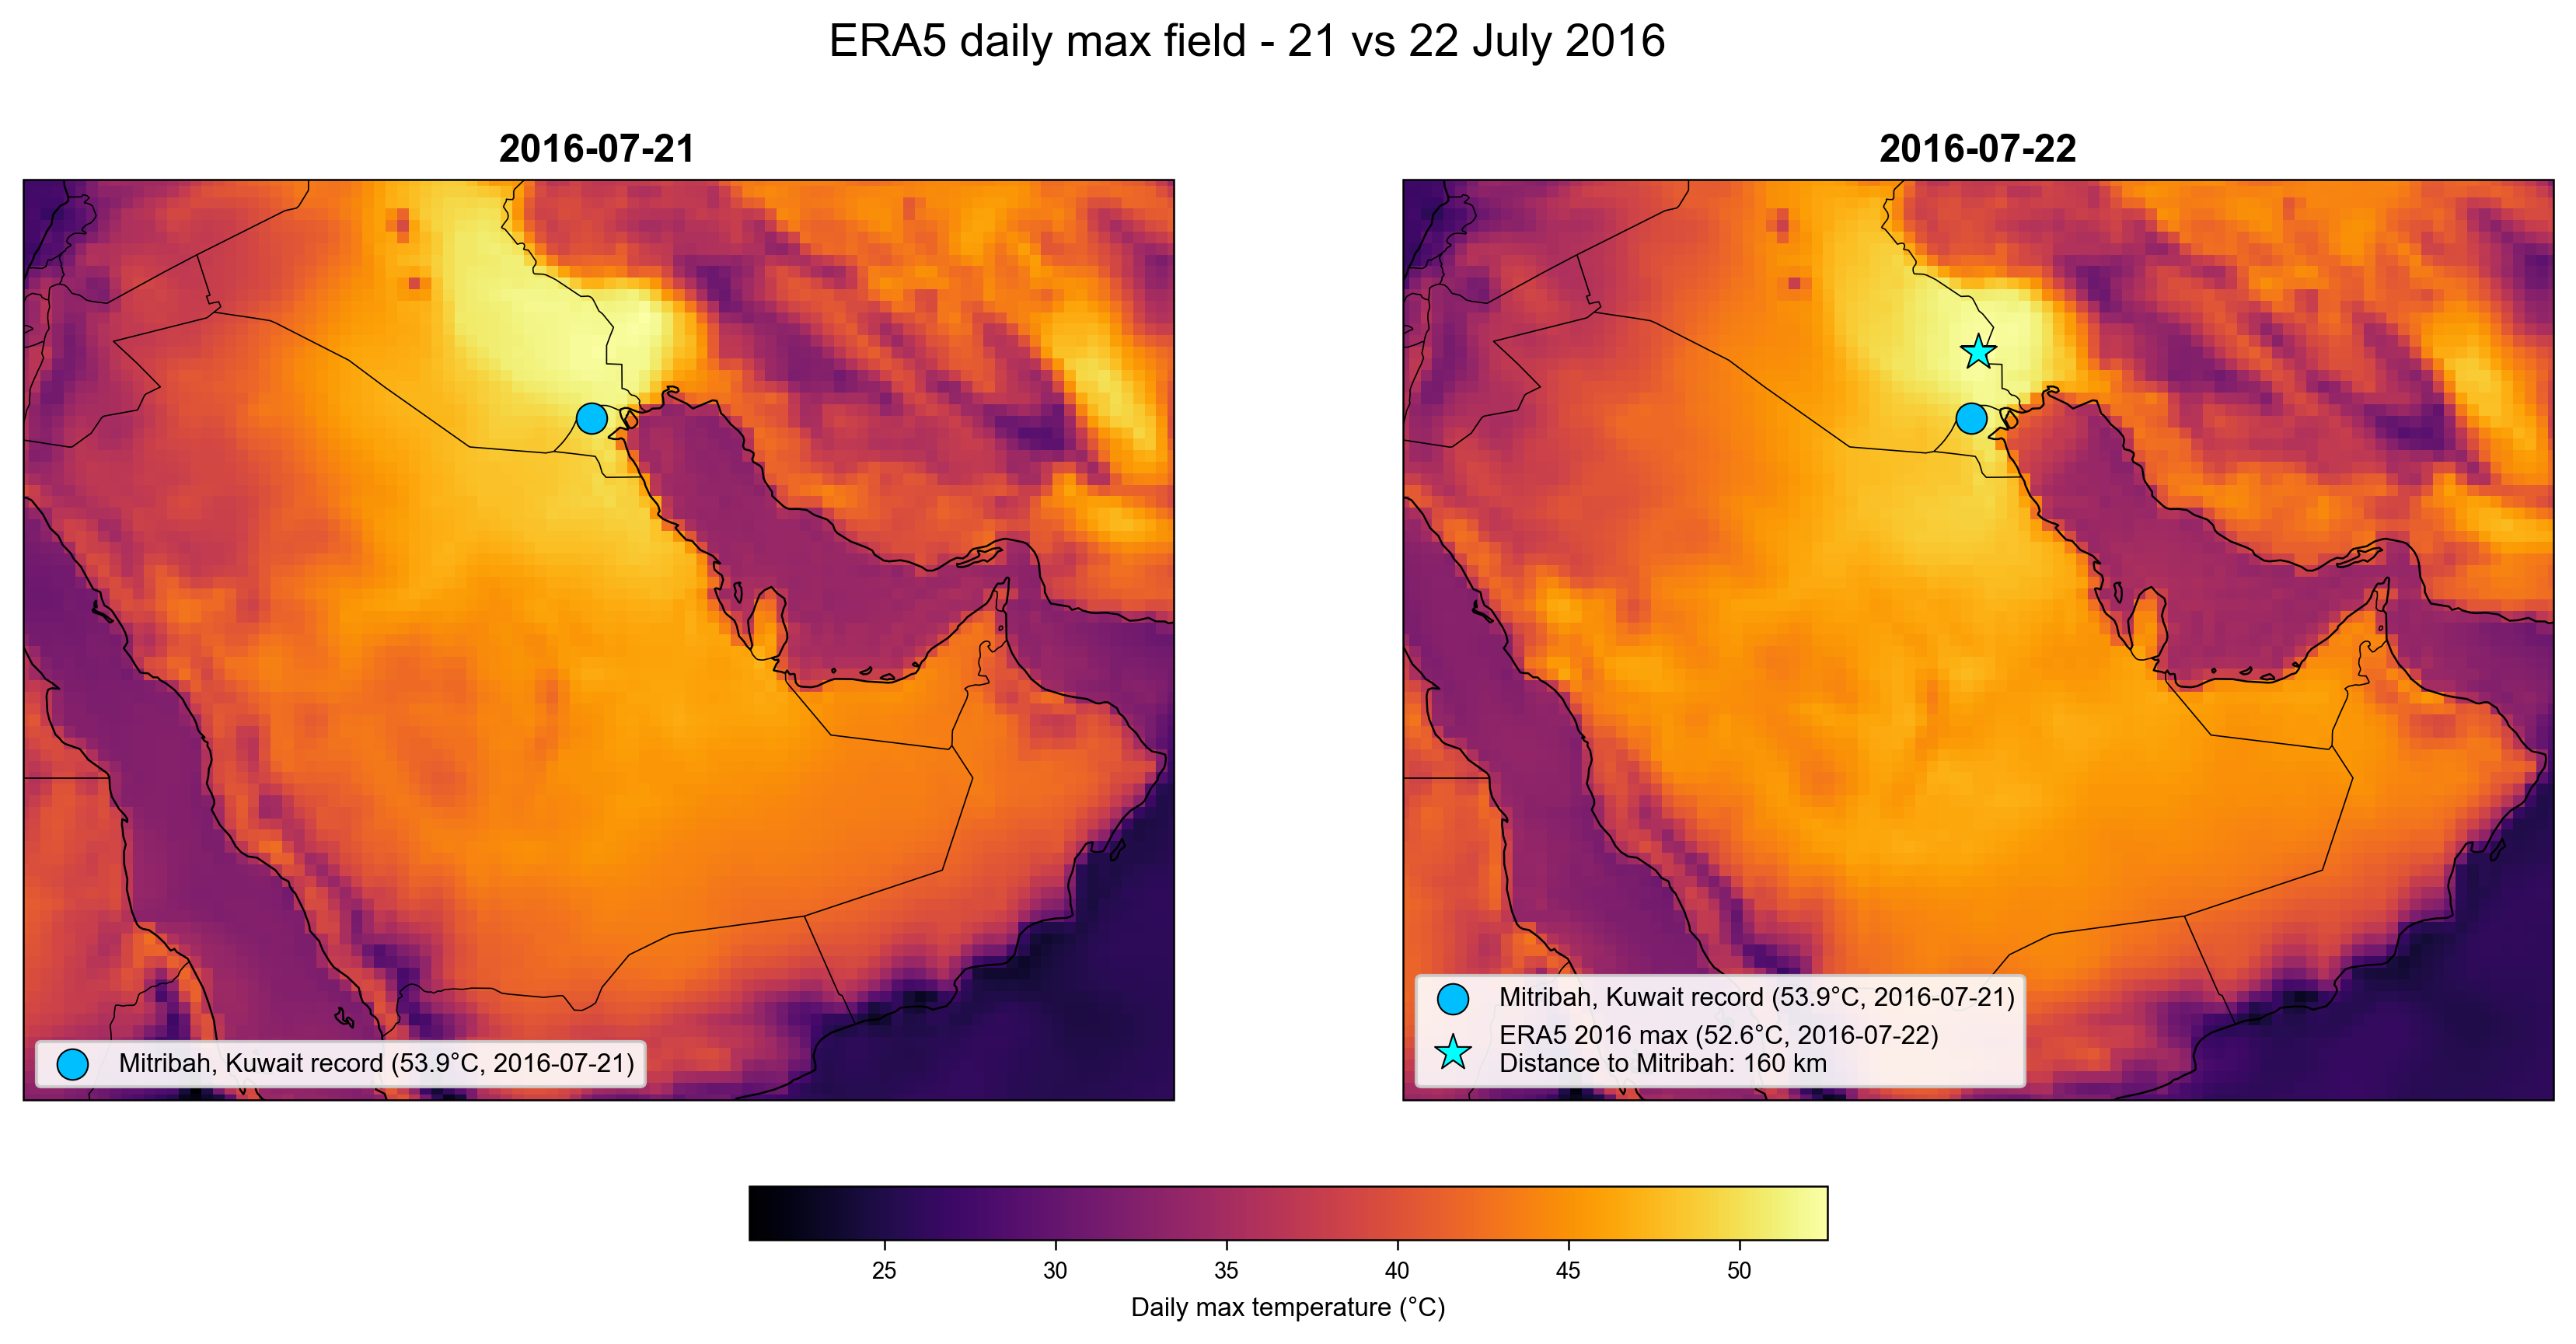

In [9]:
dates = ["2016-07-21", "2016-07-22"]

fields = {}
for d in dates:
    f = tas_daily.sel(time=d).squeeze() - 273.15
    f = f.sel(latitude=slice(35, 15), longitude=slice(35, 60))
    fields[d] = f

vmin = min(f.min().item() for f in fields.values())
vmax = max(f.max().item() for f in fields.values())

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for ax, d in zip(axes, dates):
    field_day = fields[d]
    ax.set_extent([35, 60, 15, 35], crs=ccrs.PlateCarree()) 

    mesh = ax.pcolormesh(
        field_day["longitude"], field_day["latitude"], field_day,
        cmap="inferno", shading="auto", vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree(), zorder=1,
    )
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=2)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4, zorder=2)

    ax.scatter(turbat_lon, turbat_lat, color="deepskyblue", s=90, marker="o",
               edgecolor="k", linewidth=0.5,
               transform=ccrs.PlateCarree(), zorder=5, label="Mitribah, Kuwait record (53.9°C, 2016-07-21)")

    if d == str(max_date)[:10]:
        ax.scatter(max_lon_180, max_lat, color="cyan", s=140, marker="*",
                   edgecolor="k", linewidth=0.5,
                   transform=ccrs.PlateCarree(), zorder=5,
                   label=f"ERA5 2016 max ({max_value_c:.1f}°C, {str(max_date)[:10]}) \nDistance to Mitribah: {dist_km:.0f} km")

    ax.legend(loc="lower left", fontsize=8, framealpha=0.9)
    ax.set_title(d, fontsize=12, fontweight="bold")

cbar = fig.colorbar(mesh, ax=axes, orientation="horizontal", fraction=0.05, pad=0.08)
cbar.set_label("Daily max temperature (°C)")

fig.suptitle("ERA5 daily max field - 21 vs 22 July 2016", fontsize=14)
plt.savefig(os.path.join(pathFig, "Comparison_Mitribah_map.pdf"), bbox_inches="tight")
plt.show()